# Notebook 02: Synthetic Data Generation
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization
**Input:** `data/cleaned/online_shoppers_cleaned.csv` (output of notebook 01)
**Output:** `data/synthetic/synthetic_online_shoppers.csv` (main synthetic dataset) and two baseline files.

## 1. Method and reasons
**Main method: Gaussian Copula (SDV `GaussianCopulaSynthesizer`).** A Gaussian copula models each column's own distribution (the marginal) separately from the dependence between columns, which is captured by a correlation matrix on normal scores. We chose it because:
- the project needs the **relationships between columns** to be preserved, and a copula does this explicitly through the correlation matrix;
- it handles a mix of numerical and categorical columns in one model (categorical columns are encoded and modelled jointly with the numbers);
- it is fast and has few parameters, so results are reproducible and easy to explain in the viva. A deep model such as CTGAN is more flexible but needs far more tuning and compute, and the 12,199-row table is small for it.

**Adaptation to this data.** Most numerical columns are *zero-inflated*: 47% of `Administrative`, 80% of `Informational` and 78% of `PageValues` values are exactly zero, and positive values are heavily right-skewed. A smooth distribution cannot reproduce an exact spike at zero, so we use a **hurdle design**: a zero is treated as its own state ("zero" vs "positive"), which SDV models as a separate indicator column inside the same copula (so zero-ness stays correlated with other columns), and the positive part is modelled on a **log scale**. This is an adaptation of the method, not a new method, and Section 3 shows the evidence for it.

**Baselines (for comparison only, not the main method).**
- *Bootstrap resampling* copies real rows with replacement, so it keeps relationships but **reproduces real records** (no privacy, no novelty).
- *Independent sampling* draws each column separately from its real distribution, so it matches single-column distributions but **destroys relationships between columns**.

**Reproducibility.** Seed 42 is set before every random step, and the notebook generates the data twice to prove the output is identical.

## 2. Setup

In [1]:
import json, hashlib, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sdv, rdt, copulas
from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer
from rdt.transformers import FloatFormatter

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
CLEAN_PATH = ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv"
SYN_DIR = ROOT / "data" / "synthetic"
BASE_DIR = SYN_DIR / "baselines"
FIG_DIR = ROOT / "figures" / "synthetic" / "generation"
for d in (SYN_DIR, BASE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

real = pd.read_csv(CLEAN_PATH)
N_ROWS = len(real)                      # synthetic data gets the same number of records as the real data
print("Real cleaned shape:", real.shape, "| versions: sdv", sdv.__version__, "rdt", rdt.__version__,
      "copulas", copulas.__version__, "numpy", np.__version__, "pandas", pd.__version__)

Real cleaned shape: (12199, 24) | versions: sdv 2.2.0 rdt 2.1.0 copulas 0.15.0 numpy 2.5.3 pandas 2.3.3


### 2.1 Which columns are generated and which are computed

In [2]:
BASE_NUM = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]
BASE_CAT = ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region", "TrafficType", "Revenue"]
SPECIAL = "SpecialDay"                  # only 6 distinct values (0, .2, .4, .6, .8, 1) -> modelled as categorical
COUNT_DUR = [("Administrative", "Administrative_Duration"),
             ("Informational", "Informational_Duration"),
             ("ProductRelated", "ProductRelated_Duration")]
COUNT_COLS = [c for c, _ in COUNT_DUR]
GENERATED = BASE_NUM + [SPECIAL] + BASE_CAT       # 18 columns the model generates
# Derived columns are exact functions of the base columns, so they are recomputed, never generated
DERIVED = ["Total_Pages", "Total_Duration", "Avg_Time_Per_Page", "Product_Page_Share", "Quarter", "Session_Length_Band"]
print("Generated columns:", len(GENERATED), "| derived (recomputed):", len(DERIVED))
print("SpecialDay values:", sorted(real[SPECIAL].unique()))

# Same rules as notebook 01 for the derived columns
QUARTER_MAP = {"Feb": "Q1", "Mar": "Q1", "May": "Q2", "Jun": "Q2", "Jul": "Q3", "Aug": "Q3", "Sep": "Q3",
               "Oct": "Q4", "Nov": "Q4", "Dec": "Q4"}
BAND_EDGES = real["Total_Pages"].quantile([1/3, 2/3]).tolist()      # tertile edges taken from the REAL data
print("Session_Length_Band edges (pages):", [round(e, 1) for e in BAND_EDGES])

def add_derived(d):
    # recompute the six derived columns from the base columns
    d = d.copy()
    d["Total_Pages"] = d["Administrative"] + d["Informational"] + d["ProductRelated"]
    d["Total_Duration"] = d["Administrative_Duration"] + d["Informational_Duration"] + d["ProductRelated_Duration"]
    d["Avg_Time_Per_Page"] = d["Total_Duration"] / d["Total_Pages"]
    d["Product_Page_Share"] = d["ProductRelated"] / d["Total_Pages"]
    d["Quarter"] = d["Month"].map(QUARTER_MAP)
    d["Session_Length_Band"] = pd.cut(d["Total_Pages"], bins=[0, BAND_EDGES[0], BAND_EDGES[1], np.inf],
                                      labels=["Short", "Medium", "Long"], include_lowest=True).astype(str)
    return d[list(real.columns)]

Generated columns: 18 | derived (recomputed): 6
SpecialDay values: [np.float64(0.0), np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0)]
Session_Length_Band edges (pages): [12.0, 33.0]


## 3. Validity rules (what counts as an invalid record)
A synthetic row is **valid** only if all of the following hold. These come from the real data and the project brief (no impossible values):
1. page counts are non-negative integers; durations, rates and `PageValues` are non-negative;
2. rates are at most 1, and every value is no larger than the maximum seen in the real data (this also respects the 99.5th-percentile caps from notebook 01);
3. a duration is zero whenever its page count is zero (the real data has no such contradiction);
4. a session has at least one page (`Total_Pages >= 1`);
5. categorical columns only take categories that exist in the real data.

Rows that break rule 4 are **rejected and re-drawn**; rule 3 is fixed by setting the impossible duration to zero; rules 1, 2 and 5 are enforced by clipping and by the model itself. The number of repairs is reported.

In [3]:
REAL_MAX = real[BASE_NUM].max()
CAT_LEVELS = {c: set(real[c].unique()) for c in BASE_CAT + [SPECIAL]}

def repair(a):
    # Turn raw model output into a table on the real data's scale; returns table and repair counts
    a = a.copy(); rep = {}
    for c in COUNT_COLS:
        a[c] = a[c].round()
    a[BASE_NUM] = a[BASE_NUM].fillna(0).clip(lower=0)
    a[BASE_NUM] = a[BASE_NUM].clip(upper=REAL_MAX, axis=1)
    for k, d in COUNT_DUR:
        bad = (a[k] == 0) & (a[d] > 0)
        rep[f"duration set to 0 where {k}=0"] = int(bad.sum())
        a.loc[bad, d] = 0
    for c in COUNT_COLS:
        a[c] = a[c].astype(int)
    a[SPECIAL] = a[SPECIAL].astype(float)
    return a, rep

def is_valid(a):
    pages = a[COUNT_COLS].sum(axis=1)
    ok = pages >= 1
    ok &= (a[["BounceRates", "ExitRates"]] <= 1).all(axis=1)
    for c in BASE_CAT:
        ok &= a[c].isin(CAT_LEVELS[c])
    ok &= a[SPECIAL].isin([float(x) for x in CAT_LEVELS[SPECIAL]])
    return ok

## 4. Generator configurations and a small comparison
`make_synthesizer` builds a Gaussian Copula under a configuration. We compare four configurations to justify the final one. The comparison uses simple screening scores (mean KS distance of the numerical columns, mean absolute difference of Pearson and Spearman correlations, and mean total-variation distance of categorical columns). These are **screening** scores for choosing a configuration; the full quality evaluation is in notebook 03, and all differences will be reported honestly there.

In [4]:
def training_table(hurdle, log):
    # table the copula is fitted on
    t = real[GENERATED].copy()
    t[SPECIAL] = t[SPECIAL].astype(str)
    if hurdle:                                   # zero -> missing, so 'zero' becomes its own modelled state
        for c in BASE_NUM:
            t[c] = t[c].where(t[c] != 0, np.nan)
    if log:                                      # positive parts are right-skewed -> model on log scale
        for c in BASE_NUM:
            t[c] = np.log(t[c]) if hurdle else np.log1p(t[c])
    return t

def fit_synthesizer(cfg):
    t = training_table(cfg["hurdle"], cfg["log"])
    meta = Metadata.detect_from_dataframes({"t": t})
    for c in BASE_NUM:
        meta.update_column(c, sdtype="numerical")
    for c in BASE_CAT + [SPECIAL]:
        meta.update_column(c, sdtype="categorical")
    syn = GaussianCopulaSynthesizer(meta, enforce_min_max_values=True, enforce_rounding=False,
                                    default_distribution=cfg["cat_dist"],
                                    numerical_distributions={c: cfg["num_dist"] for c in BASE_NUM})
    syn.auto_assign_transformers({"t": t})
    if cfg["hurdle"] and cfg["null_mode"] == "from_column":
        # the zero/positive indicator is a modelled column, so it stays correlated with other columns
        syn.update_transformers({c: FloatFormatter(learn_rounding_scheme=False, enforce_min_max_values=True,
                                                   missing_value_replacement="mean",
                                                   missing_value_generation="from_column") for c in BASE_NUM})
    syn.fit({"t": t})
    return syn

def sample_raw(syn, cfg, n):
    out = syn.sample(n)
    out = out["t"] if isinstance(out, dict) else out
    out = out.copy()
    if cfg["log"]:                               # back to the original scale
        for c in BASE_NUM:
            out[c] = np.exp(out[c]) if cfg["hurdle"] else np.expm1(out[c])
    return out

def screening_scores(a):
    iu = np.triu_indices(len(BASE_NUM), 1)
    ks = np.mean([stats.ks_2samp(real[c], a[c]).statistic for c in BASE_NUM])
    pe = np.abs(real[BASE_NUM].corr() - a[BASE_NUM].corr()).values[iu].mean()
    sp = np.abs(real[BASE_NUM].corr("spearman") - a[BASE_NUM].corr("spearman")).values[iu].mean()
    cats = BASE_CAT + [SPECIAL]
    tvd = np.mean([0.5 * np.abs(real[c].value_counts(normalize=True)
                                .sub(a[c].value_counts(normalize=True), fill_value=0)).sum() for c in cats])
    return {"mean_KS": ks, "mean_abs_dPearson": pe, "mean_abs_dSpearman": sp, "mean_cat_TVD": tvd}

CONFIGS = {
    "A: plain, beta":                      dict(hurdle=False, log=False, num_dist="beta", cat_dist="beta", null_mode="random"),
    "B: log1p, norm":                      dict(hurdle=False, log=True,  num_dist="norm", cat_dist="beta", null_mode="random"),
    "C: hurdle+log, nulls random":         dict(hurdle=True,  log=True,  num_dist="norm", cat_dist="beta", null_mode="random"),
    "D: hurdle+log, nulls from column":    dict(hurdle=True,  log=True,  num_dist="norm", cat_dist="truncnorm", null_mode="from_column"),
}
rows = []
for name, cfg in CONFIGS.items():
    np.random.seed(SEED)
    syn = fit_synthesizer(cfg)
    a, _ = repair(sample_raw(syn, cfg, N_ROWS))
    a[SPECIAL] = a[SPECIAL].astype(float)
    rows.append({"configuration": name, **screening_scores(a)})
selection = pd.DataFrame(rows).set_index("configuration")
display(selection.round(3))

,mean_KS,mean_abs_dPearson,mean_abs_dSpearman,mean_cat_TVD
configuration,,,,
"A: plain, beta",0.426,0.124,0.104,0.008
"B: log1p, norm",0.187,0.075,0.099,0.009
"C: hurdle+log, nulls random",0.078,0.199,0.281,0.006
"D: hurdle+log, nulls from column",0.072,0.088,0.092,0.012


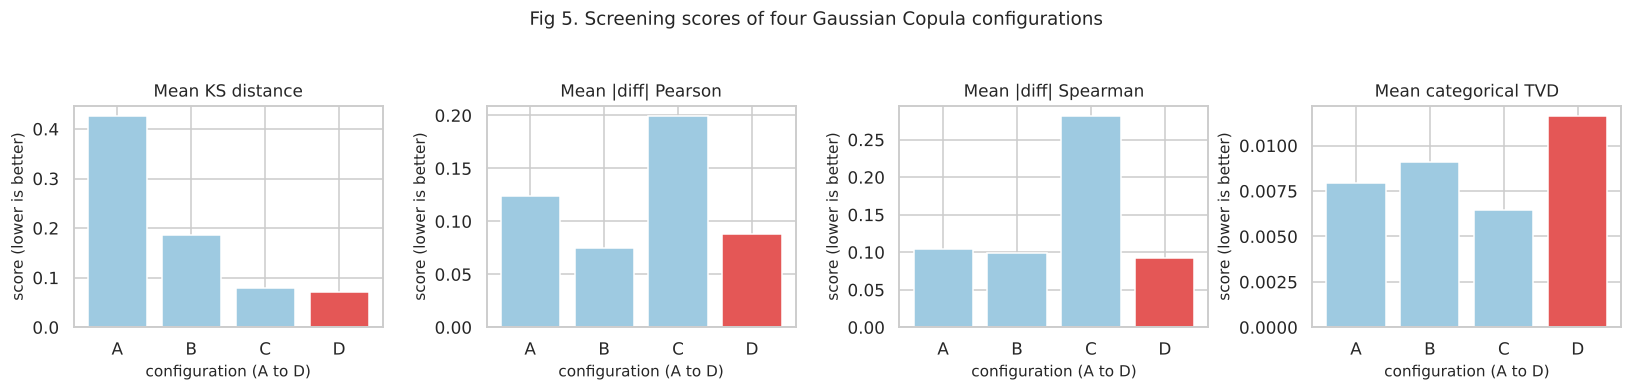

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col, ttl in zip(axes, selection.columns,
                        ["Mean KS distance", "Mean |diff| Pearson", "Mean |diff| Spearman", "Mean categorical TVD"]):
    ax.bar(range(len(selection)), selection[col], color=["#9ecae1", "#9ecae1", "#9ecae1", "#E45756"])
    ax.set_xticks(range(len(selection))); ax.set_xticklabels([n[0] for n in selection.index])
    ax.set_title(ttl); ax.set_xlabel("configuration (A to D)"); ax.set_ylabel("score (lower is better)")
fig.suptitle("Fig 5. Screening scores of four Gaussian Copula configurations", y=1.04, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig05_config_screening.png", bbox_inches="tight"); plt.show()

**Interpretation.** Configuration A (a plain copula) fits zero-inflated columns badly: its KS distance is the largest because it cannot create exact zeros. Using a log scale alone (B) helps a lot for the marginals (KS falls from 0.43 to 0.19) but still cannot make exact zeros. Treating zeros as their own state (C and D) cuts the marginal error again, but only D, where the zero indicator is a modelled column, also keeps correlations close: in C the zeros are placed independently of the other columns, which raises the correlation error to about 0.2 to 0.3. D has the lowest KS distance and the lowest Spearman error, a Pearson error close to the best (B is slightly lower, 0.075 vs 0.088), and a categorical error that is the highest of the four but still very small (0.012). Because it is the only configuration that handles both the zero spikes and the dependence, D is the final configuration. These are screening scores, not proof of fidelity; notebook 03 evaluates the result in full.

## 5. Generate the main synthetic dataset

In [6]:
FINAL_CFG = CONFIGS["D: hurdle+log, nulls from column"]

def generate(cfg, n, seed):
    # Fit, sample, repair and reject invalid rows until n valid rows exist
    np.random.seed(seed)
    syn = fit_synthesizer(cfg)
    kept, repairs, rejected, tries = [], {}, 0, 0
    need = n
    while need > 0 and tries < 20:
        tries += 1
        raw, rep = repair(sample_raw(syn, cfg, int(need * 1.2) + 50))
        for k, v in rep.items():
            repairs[k] = repairs.get(k, 0) + v
        ok = is_valid(raw)
        rejected += int((~ok).sum())
        kept.append(raw[ok]); need = n - sum(len(k) for k in kept)
    out = pd.concat(kept).iloc[:n].reset_index(drop=True)
    return out, repairs, rejected, tries

t0 = time.time()
syn_base, repairs, rejected, tries = generate(FINAL_CFG, N_ROWS, SEED)
synthetic = add_derived(syn_base)
print(f"Generated {len(synthetic)} rows in {time.time() - t0:.1f}s | rejected rows: {rejected} | sampling rounds: {tries}")
print("Repairs:", repairs)
synthetic.head()

Generated 12199 rows in 1.2s | rejected rows: 0 | sampling rounds: 1
Repairs: {'duration set to 0 where Administrative=0': 340, 'duration set to 0 where Informational=0': 503, 'duration set to 0 where ProductRelated=0': 0}


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month,Quarter,VisitorType,Weekend,OperatingSystems,Browser,Region,TrafficType,Session_Length_Band,Revenue
0,3,22.247188,0,0.000000,24,1445.062629,0.015610,0.010847,11.164300,0.0,...,Nov,Q4,Returning_Visitor,Weekend,OS_2,Browser_2,Region_3,Traffic_2,Medium,No_Purchase
1,0,0.000000,2,66.376805,8,936.571570,0.041568,0.054702,0.000000,0.0,...,Mar,Q1,Returning_Visitor,Weekday,OS_2,Browser_2,Region_3,Traffic_3,Short,Purchase
2,0,0.000000,0,0.000000,4,205.445393,0.000000,0.032714,0.000000,0.0,...,Nov,Q4,New_Visitor,Weekday,OS_1,Browser_1,Region_1,Traffic_6,Short,No_Purchase
3,0,0.000000,2,80.764043,10,364.970249,0.130787,0.200000,17.349723,0.8,...,Nov,Q4,Returning_Visitor,Weekday,OS_2,Browser_1,Region_2,Traffic_2,Short,No_Purchase
4,2,213.185264,0,0.000000,39,257.407015,0.000000,0.015894,0.000000,0.0,...,Oct,Q4,Other,Weekday,OS_2,Browser_1,Region_5,Traffic_1,Long,Purchase


## 6. Baselines (comparison only)

In [7]:
def bootstrap_baseline(n, seed):
    # resample real rows with replacement (copies real records)
    rng = np.random.default_rng(seed)
    return real.iloc[rng.integers(0, len(real), n)].reset_index(drop=True)

def independent_baseline(n, seed):
    # draw every generated column separately from its real distribution (destroys relationships)
    rng = np.random.default_rng(seed)
    kept, need = [], n
    while need > 0:
        m = int(need * 1.2) + 50
        d = pd.DataFrame({c: rng.choice(real[c].to_numpy(), m) for c in GENERATED})
        d, _ = repair(d)
        d = d[is_valid(d)]
        kept.append(d); need = n - sum(len(k) for k in kept)
    return add_derived(pd.concat(kept).iloc[:n].reset_index(drop=True))

baseline_boot = bootstrap_baseline(N_ROWS, SEED)
baseline_indep = independent_baseline(N_ROWS, SEED)
print("bootstrap:", baseline_boot.shape, "| independent:", baseline_indep.shape)

bootstrap: (12199, 24) | independent: (12199, 24)


## 7. Checks: same schema, no invalid values

In [8]:
def check_dataset(d, name):
    problems = []
    if list(d.columns) != list(real.columns): problems.append("columns differ")
    if len(d) < len(real): problems.append("fewer rows than real")
    for c in real.columns:
        if real[c].dtype.kind != d[c].dtype.kind and not (real[c].dtype.kind in "OU" and d[c].dtype.kind in "OU"):
            problems.append(f"dtype of {c}: {d[c].dtype} vs {real[c].dtype}")
    if d.isna().any().any(): problems.append("missing values")
    num = d.select_dtypes("number")
    if (num < 0).any().any(): problems.append("negative values")
    if (d[["BounceRates", "ExitRates", "SpecialDay", "Product_Page_Share"]] > 1).any().any(): problems.append("value above 1")
    if (d[BASE_NUM] > REAL_MAX).any().any(): problems.append("value above real maximum")
    if (d["Total_Pages"] < 1).any(): problems.append("session with no pages")
    for k, dd in COUNT_DUR:
        if ((d[k] == 0) & (d[dd] > 0)).any(): problems.append(f"{dd} > 0 with {k} = 0")
    for c in BASE_CAT + ["Quarter", "Session_Length_Band"]:
        if not set(d[c]).issubset(set(real[c])): problems.append(f"new category in {c}")
    print(f"{name:12s}", "OK: valid, same columns and dtypes" if not problems else "PROBLEMS: " + "; ".join(problems))
    return not problems

assert check_dataset(synthetic, "gaussian copula")
assert check_dataset(baseline_boot, "bootstrap")
assert check_dataset(baseline_indep, "independent")
display(pd.DataFrame({"real": real.dtypes.astype(str), "synthetic": synthetic.dtypes.astype(str)}).T)

gaussian copula OK: valid, same columns and dtypes
bootstrap    OK: valid, same columns and dtypes
independent  OK: valid, same columns and dtypes


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month,Quarter,VisitorType,Weekend,OperatingSystems,Browser,Region,TrafficType,Session_Length_Band,Revenue
real,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,...,object,object,object,object,object,object,object,object,object,object
synthetic,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,...,object,object,object,object,object,object,object,object,object,object


## 8. Preliminary comparison of the three generators
Screening scores plus how many synthetic rows are exact copies of a real row. The full evaluation (statistics, distributions, heatmaps, tests) follows in notebook 03.

In [9]:
def exact_copies(d):
    return int(d.merge(real.drop_duplicates(), how="inner", on=list(real.columns)).shape[0])

comp = pd.DataFrame({"Gaussian Copula (main)": screening_scores(synthetic),
                     "Bootstrap (baseline)": screening_scores(baseline_boot),
                     "Independent (baseline)": screening_scores(baseline_indep)}).T
comp["rows identical to a real row"] = [exact_copies(synthetic), exact_copies(baseline_boot), exact_copies(baseline_indep)]
comp["purchase rate"] = [(d["Revenue"] == "Purchase").mean() for d in (synthetic, baseline_boot, baseline_indep)]
display(comp.round(3))
print(f"Real purchase rate: {(real['Revenue'] == 'Purchase').mean():.3f}")

,mean_KS,mean_abs_dPearson,mean_abs_dSpearman,mean_cat_TVD,rows identical to a real row,purchase rate
Gaussian Copula (main),0.072,0.088,0.092,0.012,0,0.142
Bootstrap (baseline),0.005,0.005,0.004,0.006,12199,0.156
Independent (baseline),0.048,0.267,0.328,0.006,0,0.150


Real purchase rate: 0.156


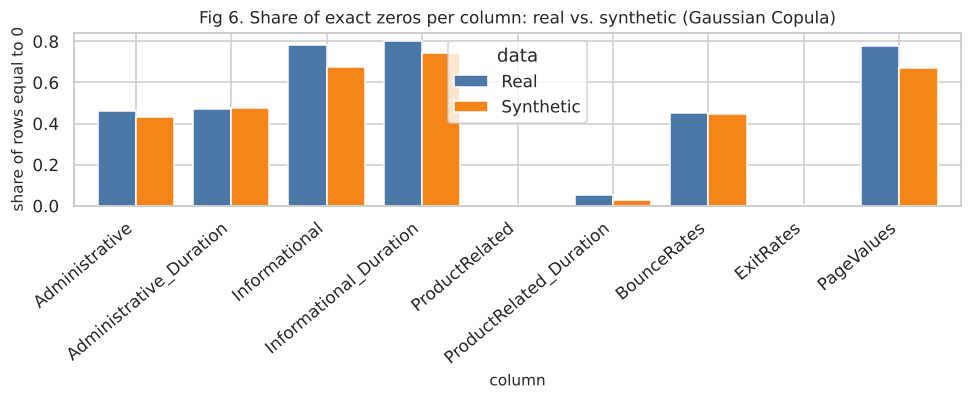

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
Real,0.462,0.473,0.784,0.803,0.003,0.051,0.452,0.006,0.776
Synthetic,0.432,0.478,0.677,0.743,0.000,0.027,0.445,0.000,0.671


In [10]:
zero_share = pd.DataFrame({"Real": (real[BASE_NUM] == 0).mean(), "Synthetic": (synthetic[BASE_NUM] == 0).mean()})
fig, ax = plt.subplots(figsize=(9, 3.8))
zero_share.plot.bar(ax=ax, color=["#4C78A8", "#F58518"], width=0.8)
ax.set_title("Fig 6. Share of exact zeros per column: real vs. synthetic (Gaussian Copula)")
ax.set_xlabel("column"); ax.set_ylabel("share of rows equal to 0"); ax.legend(title="data")
plt.xticks(rotation=40, ha="right"); fig.tight_layout()
fig.savefig(FIG_DIR / "fig06_zero_share.png", bbox_inches="tight"); plt.show()
display(zero_share.round(3).T)

**Interpretation.** The Gaussian Copula keeps correlations much closer than independent sampling (mean absolute Pearson difference 0.09 vs 0.27), and, unlike bootstrap, it produces no rows identical to a real row. Bootstrap scores best on distance measures only because it copies real rows (all 12,199 are exact copies). Figure 6 shows the zero-spike is reproduced only approximately: `Informational` and `PageValues` have clearly fewer zeros in the synthetic data (about 68% and 67%) than in the real data (about 78%), and `ProductRelated` has no zeros at all, against 0.3% in the real data. The synthetic purchase rate is also lower than the real one (14.2% vs 15.6%). These are known weaknesses of the method; they will be quantified in the quality evaluation and discussed in the limitations.

## 9. Reproducibility check: regenerate with the same seed

In [11]:
again_base, _, _, _ = generate(FINAL_CFG, N_ROWS, SEED)
again = add_derived(again_base)
same = synthetic.equals(again)
print("Regenerated data identical to first run:", same)
assert same, "Generation is not reproducible"

Regenerated data identical to first run: True


## 10. Save the datasets and the generation settings

In [12]:
synthetic.to_csv(SYN_DIR / "synthetic_online_shoppers.csv", index=False)
baseline_boot.to_csv(BASE_DIR / "baseline_bootstrap.csv", index=False)
baseline_indep.to_csv(BASE_DIR / "baseline_independent.csv", index=False)

settings = {
    "method": "SDV GaussianCopulaSynthesizer with hurdle (zero indicator from column) and log transform of positive parts",
    "seed": SEED, "n_rows": int(N_ROWS), "configuration": FINAL_CFG,
    "generated_columns": GENERATED, "recomputed_derived_columns": DERIVED,
    "session_length_band_edges_pages": BAND_EDGES,
    "versions": {"sdv": sdv.__version__, "rdt": rdt.__version__, "copulas": copulas.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
    "rejected_rows_during_generation": rejected, "repairs": repairs,
}
(SYN_DIR / "generation_settings.json").write_text(json.dumps(settings, indent=2))
for p in (SYN_DIR / "synthetic_online_shoppers.csv", BASE_DIR / "baseline_bootstrap.csv", BASE_DIR / "baseline_independent.csv"):
    print("Saved", p.relative_to(ROOT), f"({len(pd.read_csv(p))} rows)")

Saved data/synthetic/synthetic_online_shoppers.csv (12199 rows)
Saved data/synthetic/baselines/baseline_bootstrap.csv (12199 rows)
Saved data/synthetic/baselines/baseline_independent.csv (12199 rows)


## 11. Summary of Phase 3
- Main method: SDV Gaussian Copula with a hurdle (zero indicator) and log scale, seed 42; same 24 columns and dtypes as the cleaned real data, 12,199 rows.
- The 18 base columns are generated; the 6 derived columns are recomputed so they cannot contradict the base columns.
- Invalid records are prevented by clipping, repair and rejection; the counts are reported above.
- Baselines (bootstrap, independent) are saved separately for comparison and are not used as the main data.
- Known weakness: zero-inflated columns keep slightly fewer zeros than the real data. Full quality evaluation comes next (notebook 03).
- Repairs during generation: the model's separate zero indicators sometimes disagree with each other, so 340 durations (Administrative) and 503 durations (Informational) were set to zero where the matching page count was zero (about 2.8% and 4.1% of rows). No rows were rejected.